## 0. SETUP


In [1]:
from google.colab import drive
drive.mount("/content/drive")
%pip install -q pyuvdata tqdm

import os, shutil, torch
DRIVE_TENSORS = "/content/drive/MyDrive/cs163_tensors"
TENSORS = "/content/cs163_tensors"
if not os.path.exists(f"{TENSORS}/X.npy"):
    shutil.copytree(DRIVE_TENSORS, TENSORS)
print("tensors", TENSORS, "cuda" if torch.cuda.is_available() else "CPU")

Mounted at /content/drive
tensors /content/cs163_tensors cuda


## 1. SETTINGS

In [15]:
TENSORS  = "/content/cs163_tensors"
RAW_DIR  = "/content/drive/MyDrive/CS 163/cs163_data"
N = N_FULL = 214
K = 214
HIDDEN, LR, EPOCHS, BS = 256, 1e-3, 200, 32
IMG_PIX, IMG_FOV = 32, 0.001
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device", device, "lr", LR)

device cuda lr 0.001


## 2. LIBRARY — run once, do not edit


In [3]:
import glob, gc, os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pyuvdata import UVData

assert 1 <= K <= N_FULL


class AntennaMLP(nn.Module):
    """Shared MLP: antenna i is predicted from its row and column of V."""
    def __init__(self, n, hidden=HIDDEN):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4 * n, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x):                              # (B, 2, n, n) → (B, 2n)
        b, _, n, _ = x.shape
        row = x.permute(0, 2, 1, 3).reshape(b, n, 2 * n)
        col = x.permute(0, 3, 1, 2).reshape(b, n, 2 * n)
        g = self.net(torch.cat([row, col], -1))
        return torch.cat([g[..., 0], g[..., 1]], 1)


def mlp_input(x):
    return x / (x.flatten(1).std(1).view(-1, 1, 1, 1) + 1e-6)


def batches(X, Y, M, idx, bs, shuffle=False):
    if shuffle:
        idx = idx[torch.randperm(len(idx), device=device)]
    for s in range(0, len(idx), bs):
        b = idx[s:s + bs]
        yield X[b].float(), Y[b], M[b]


def build_dft():
    f = sorted(glob.glob(f"{RAW_DIR}/uncalib_data_*.uvfits"))[0]
    uv = UVData(); uv.read(f, run_check=False)
    ants = np.union1d(uv.ant_1_array, uv.ant_2_array)
    i = np.searchsorted(ants, uv.ant_1_array)
    j = np.searchsorted(ants, uv.ant_2_array)
    keep = i != j
    i, j = i[keep], j[keep]
    lam = 299792458.0 / float(uv.freq_array.ravel()[0])
    u, v = (uv.uvw_array[keep, :2] / lam).T
    l = np.linspace(-IMG_FOV, IMG_FOV, IMG_PIX)
    L, Mm = np.meshgrid(l, l)
    phase = 2j * np.pi * (np.outer(L.ravel(), u) + np.outer(Mm.ravel(), v))
    A = torch.from_numpy(np.exp(phase).astype(np.complex64)).to(device)
    return A, torch.from_numpy(i).to(device), torch.from_numpy(j).to(device)


def dft_for(keep):
    A, bi, bj = build_dft()
    pos = torch.full((N_FULL,), -1, dtype=torch.long, device=bi.device)
    pos[keep.to(bi.device)] = torch.arange(keep.numel(), device=bi.device)
    ok = (pos[bi] >= 0) & (pos[bj] >= 0)
    if not bool(ok.any()):
        raise RuntimeError(f"no baselines among the {keep.numel()} selected antennas")
    return A[:, ok], pos[bi[ok]], pos[bj[ok]]


def to_c(t):
    return torch.complex(t[:, 0], t[:, 1]) if t.dim() == 3 else torch.complex(t[:, :N], t[:, N:])


def calibrate(V, g, bi, bj, eps=1e-3):
    G = g[:, bi] * g[:, bj].conj()
    G = torch.where(G.abs() < eps, eps * torch.ones_like(G), G)
    return V[:, bi, bj] / G


def make_image(Vb, A):
    return (Vb @ A.T).real.reshape(-1, IMG_PIX, IMG_PIX) / A.shape[1]


def gain_loss(pred, y, m):
    gp, gt, w = to_c(pred), to_c(y), m.float()
    ph = torch.angle((gp * gt.conj() * w).sum(1, keepdim=True)).detach()
    return ((gp * torch.exp(-1j * ph) - gt).abs() ** 2 * w).sum() / w.sum()


def image_loss(pred, x, y, m, A, bi, bj):
    V = torch.complex(x[:, 0], x[:, 1])
    ok = (m[:, bi] & m[:, bj]).float()
    img_pred = make_image(calibrate(V, to_c(pred), bi, bj) * ok, A)
    with torch.no_grad():
        ref = make_image(calibrate(V, to_c(y), bi, bj) * ok, A)
    scale = ref.abs().mean() + 1e-8
    return (((img_pred - ref) / scale) ** 2).mean()


def load_k(k):
    X = np.load(f"{TENSORS}/X.npy", mmap_mode="r")
    Y = np.load(f"{TENSORS}/Y.npy", mmap_mode="r")
    M = np.load(f"{TENSORS}/M.npy", mmap_mode="r")
    Xk = torch.from_numpy(np.ascontiguousarray(X[:, :, :k, :k])).to(device)
    Yk = torch.from_numpy(np.ascontiguousarray(Y[:, :, :k])).to(device)
    Mk = torch.from_numpy(np.ascontiguousarray(M[:, :k])).to(device)
    return (Xk, Yk, Mk), torch.arange(k, device=device)


def make_tvt(n, seed=0):
    perm = torch.randperm(n, generator=torch.Generator().manual_seed(seed)).to(device)
    n_tr, n_va = int(0.8 * n), int(0.1 * n)
    return {"train": perm[:n_tr], "val": perm[n_tr:n_tr + n_va], "test": perm[n_tr + n_va:]}


def run_epoch(model, data, idx, A, bi, bj, opt=None):
    X, Y, M = data
    tot = {"gain": 0.0, "image": 0.0, "total": 0.0}; n = 0
    model.train(opt is not None)
    for x, y, m in batches(X, Y, M, idx, BS, shuffle=opt is not None):
        with torch.set_grad_enabled(opt is not None):
            pred = model(mlp_input(x))
            lg = gain_loss(pred, y, m)
            li = image_loss(pred, x, y, m, A, bi, bj)
            loss = lg * li
            if opt is not None:
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()
        for key, v in zip(tot, (lg, li, loss)):
            tot[key] += v.item() * len(x)
        n += len(x)
    return {k: v / n for k, v in tot.items()}


def fmt(tag, d):
    return f"{tag} gain {d['gain']:.4f} image {d['image']:.4f} total {d['total']:.4f}"

print("library ready", device, "lr", LR)


library ready cuda lr 0.001


## 3. TRAIN


/tmp/ipykernel_1082/1441306924.py:102: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  Xk = torch.from_numpy(np.ascontiguousarray(X[:, :, :k, :k])).to(device)


214x214  baselines 22791  train 8000  val 1000  test 1000
AntennaMLP  0.286M  hidden 256
epoch  0 | train gain 2.1943 image 178.3903 total 183.1217 | val gain 2.1380 image 1.8764 total 4.0120
epoch  1 | train gain 2.0748 image 1.8148 total 3.7636 | val gain 2.1305 image 1.7142 total 3.6522
epoch  2 | train gain 2.0213 image 1.6989 total 3.4322 | val gain 2.0613 image 1.6287 total 3.3576
epoch  3 | train gain 1.9783 image 1.6248 total 3.2135 | val gain 1.9481 image 1.6547 total 3.2237
epoch  4 | train gain 1.9326 image 1.5827 total 3.0566 | val gain 1.8948 image 1.6202 total 3.0701
epoch  5 | train gain 1.8792 image 1.5510 total 2.9136 | val gain 1.8658 image 1.5842 total 2.9561
epoch  6 | train gain 1.8268 image 1.5273 total 2.7891 | val gain 1.8531 image 1.5420 total 2.8577
epoch  7 | train gain 1.7862 image 1.5083 total 2.6931 | val gain 1.8440 image 1.5287 total 2.8193
epoch  8 | train gain 1.7447 image 1.4954 total 2.6082 | val gain 1.7332 image 1.5741 total 2.7282
epoch  9 | train

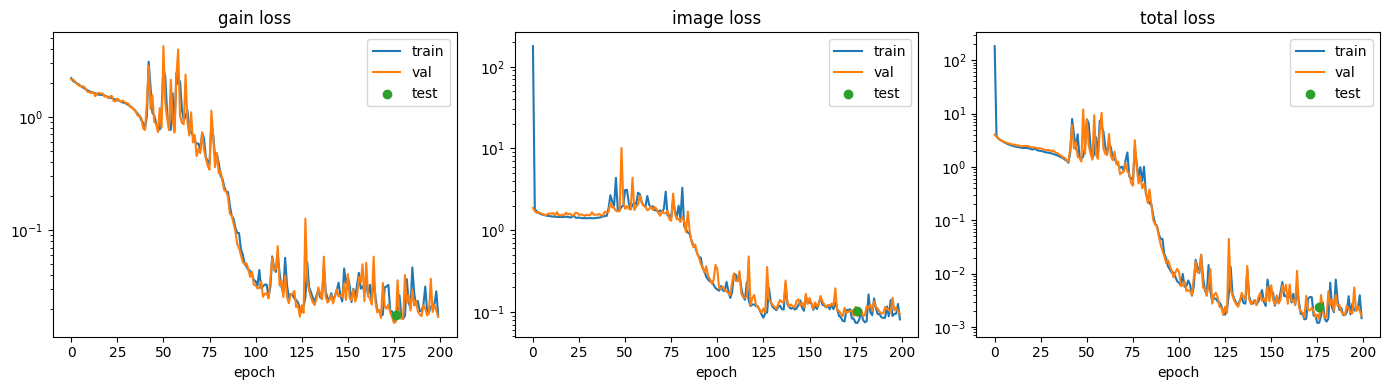

In [4]:
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

N = K
data, keep = load_k(K)
splits = make_tvt(len(data[0]))
A, bi, bj = dft_for(keep)
print(f"{K}x{K}  baselines {A.shape[1]}  "
      + "  ".join(f"{name} {len(idx)}" for name, idx in splits.items()))

model = AntennaMLP(K).to(device)
print(f"{type(model).__name__}  {sum(p.numel() for p in model.parameters())/1e6:.3f}M  hidden {HIDDEN}")

opt = torch.optim.Adam(model.parameters(), lr=LR)
SAVE = f"/content/drive/MyDrive/mlp_k{K}.pt"
hist = {"train": [], "val": []}
best, best_ep = float("inf"), -1

for ep in range(EPOCHS):
    tr = run_epoch(model, data, splits["train"], A, bi, bj, opt)
    va = run_epoch(model, data, splits["val"], A, bi, bj)
    hist["train"].append(tr); hist["val"].append(va)
    print(f"epoch {ep:2d} | {fmt('train', tr)} | {fmt('val', va)}")
    if va["total"] < best:
        best, best_ep = va["total"], ep
        torch.save(model.state_dict(), SAVE)

model.load_state_dict(torch.load(SAVE, map_location=device))
final = run_epoch(model, data, splits["test"], A, bi, bj)
print(f"best val epoch {best_ep} | {fmt('test', final)}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, key in zip(axes, ("gain", "image", "total")):
    for split in ("train", "val"):
        ax.plot([h[key] for h in hist[split]], label=split)
    ax.scatter([best_ep], [final[key]], color="C2", zorder=3, label="test")
    ax.set_title(f"{key} loss"); ax.set_xlabel("epoch"); ax.set_yscale("log"); ax.legend()
fig.tight_layout()
fig.savefig(SAVE.replace(".pt", "_loss.png"), dpi=150)
plt.show()


## 4. GAINS

Red = true, blue = predicted. Global phase removed.


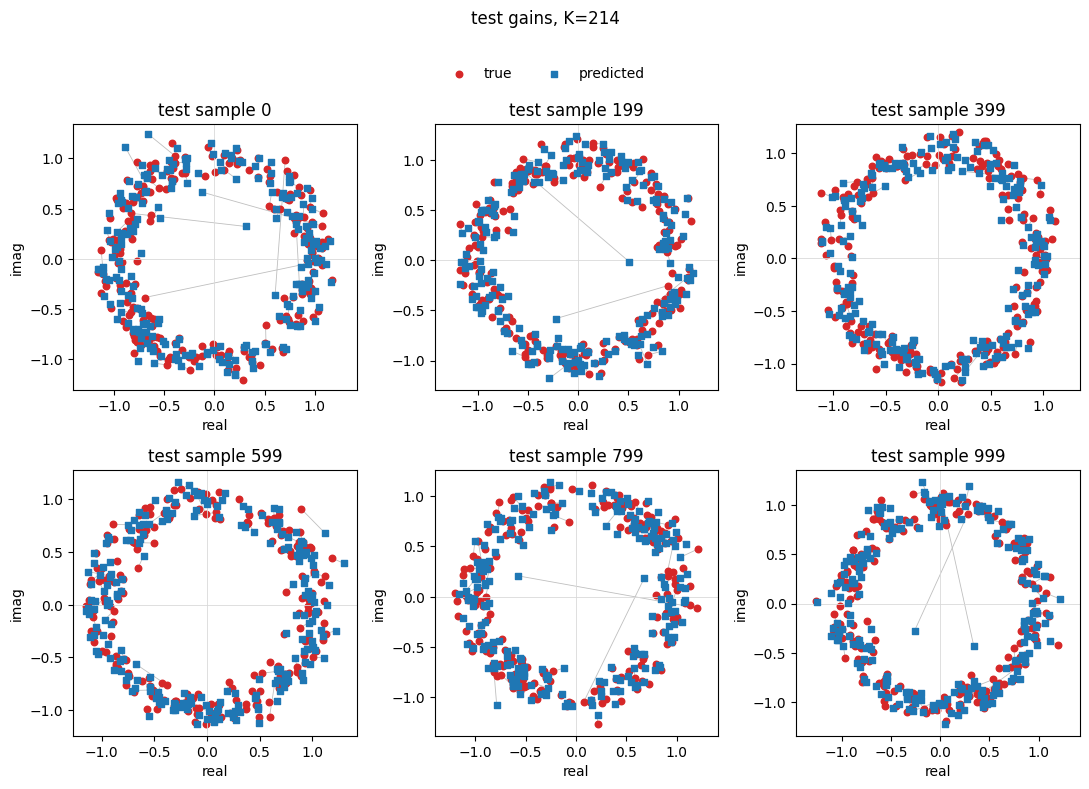

In [5]:
@torch.no_grad()
def collect_test_gains(model, data, idx):
    model.eval()
    preds, trues = [], []
    X, Y, M = data
    for x, y, m in batches(X, Y, M, idx, BS, shuffle=False):
        gp, gt = to_c(model(mlp_input(x))), to_c(y)
        ph = torch.angle((gp * gt.conj() * m.float()).sum(1, keepdim=True))
        preds.append((gp * torch.exp(-1j * ph)).cpu())
        trues.append(gt.cpu())
    return torch.cat(preds), torch.cat(trues)

model.load_state_dict(torch.load(f"/content/drive/MyDrive/mlp_k{K}.pt", map_location=device))
gp, gt = collect_test_gains(model, data, splits["test"])
show = torch.linspace(0, len(gp) - 1, 6).long()

fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
for ax, i in zip(axes.ravel(), show.tolist()):
    t, p = gt[i], gp[i]
    for a in range(t.shape[0]):
        ax.plot([t[a].real, p[a].real], [t[a].imag, p[a].imag], color="0.75", lw=0.6, zorder=1)
    ax.scatter(t.real, t.imag, s=22, c="#d62728", label="true", zorder=2)
    ax.scatter(p.real, p.imag, s=22, c="#1f77b4", marker="s", label="predicted", zorder=3)
    ax.axhline(0, color="0.85", lw=0.6); ax.axvline(0, color="0.85", lw=0.6)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_title(f"test sample {i}")
    ax.set_xlabel("real"); ax.set_ylabel("imag")
h, lab = axes[0, 0].get_legend_handles_labels()
fig.legend(h[:2], lab[:2], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"test gains, K={K}", y=1.06)
fig.tight_layout()
fig.savefig(f"/content/drive/MyDrive/mlp_k{K}_gains.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. IMAGES

Dirty / expected (true gains) / restored (predicted gains). Same DFT as the loss.


In [21]:
import torch, numpy as np, matplotlib.pyplot as plt

def ifft_from_g(V, g, alive):
    G = g[:, None] * np.conj(g)[None, :]
    ok = alive[:, None] & alive[None, :] & (np.abs(G) > 1e-6)
    sky_V = np.zeros(V.shape, np.complex64)
    sky_V[ok] = (V[ok] / G[ok]).astype(np.complex64)
    grid = np.zeros((NPIX, NPIX), np.complex64)
    wgt  = np.zeros((NPIX, NPIX), np.float32)
    np.add.at(grid, (vi, ui), sky_V[ii, jj])
    np.add.at(wgt,  (vi, ui), 1.0)
    grid /= np.maximum(wgt, 1.0)
    return np.fft.fftshift(np.fft.ifft2(np.fft.ifftshift(grid))).real

model.eval()
model.load_state_dict(torch.load(f"/content/drive/MyDrive/mlp_k{K}.pt", map_location=device, weights_only=False))
Xk, Yk, Mk = data
idx = splits["test"]
show = torch.linspace(0, len(idx) - 1, 4).long()
b = idx[show].cpu().numpy()

titles = ("dirty", "expected (true gains)", "predicted")
fig, axes = plt.subplots(len(b), 3, figsize=(12, 3.4 * len(b)))
for r, si in enumerate(b):
    V = X[si, 0].astype(np.float32) + 1j * X[si, 1].astype(np.float32)
    alive = np.asarray(M[si])
    gt = Y[si, 0] + 1j * Y[si, 1]
    x = torch.from_numpy(np.stack([V.real, V.imag])).unsqueeze(0).float().to(device)
    gp = to_c(model(mlp_input(x)))[0].detach().cpu().numpy()
    row = (
        ifft_from_g(V, np.ones_like(gt), alive),
        ifft_from_g(V, gt, alive),
        ifft_from_g(V, gp, alive),
    )
    lo, hi = np.percentile(np.stack(row), [1, 99.5])
    for c, (im, title) in enumerate(zip(row, titles)):
        ax = axes[r, c]
        ax.imshow(im, origin="lower", cmap="plasma", vmin=lo, vmax=hi)
        if r == 0: ax.set_title(title)
        ax.set_xticks([]); ax.set_yticks([])
        if c == 0: ax.set_ylabel(f"sample {int(si)}")
fig.suptitle(f"ifft2 {NPIX}×{NPIX}  dirty / expected / predicted", y=1.01)
fig.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.